# Wafer assembly: dies on a 4 in and a 6 in wafer

This notebook packs square dies on a round wafer with a side notch, names them (rows are letters, columns are numbers),
places real chip layouts on them and writes the wafer OAS. The wafer outline is on layer **500/0** and everything
else drawn at wafer level (die labels, die outlines, alignment and orientation marks) on **501/0**.

| Part | What it shows |
|---|---|
| 1 Setup and chips | three chips (4.5, 7.5 and 9 mm) written once as OAS files |
| 2 Four inch, dense | 7.5 mm dies fill the whole 100 mm wafer |
| 3 Four inch, centred | the same dies only inside a 30 mm radius, with an offset |
| 4 Four inch, mixed | 5, 7.5 and 10 mm dies on one wafer (bands of rows) |
| 5 Six inch | 10 mm dies dense, 7.5 mm dies centred |
| 6 Zoom | a few dies with their labels, in KLayout |

Everything runs without KLayout open (`QCC_LIVE=0`); pictures are rendered headless. Output goes to `build/wafer/`.
Docs: `docs/library/wafer.md`. Code: `src/quantcore_circuits/layouts/wafers/wafer.py`.

## 1 Setup and chips

In [1]:
import os

os.environ["QCC_LIVE"] = "0"
from pathlib import Path

from IPython.display import Image, Markdown, display

from quantcore_circuits.assembly import build, write_layout
from quantcore_circuits.designer import Designer
from quantcore_circuits.layouts.wafers.wafer import Wafer
from quantcore_circuits.live.snapshot import snapshot

REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
OUT = REPO / "build" / "wafer"
(OUT / "chips").mkdir(parents=True, exist_ok=True)

The chips come from existing designs (the JSON files are only read, never rewritten): the legacy cryogenic test chip
(7.5 mm) and the Metal four-qubit chip (9.0 x 6.5 mm). A 4.5 mm test chip for the 5 mm dies is made here with a
`Designer`. Each is built headless and written once to `build/wafer/chips/`; the wafer takes those OAS files.

In [2]:
mini = Designer("mini_pads", box=(0, 0, 4500, 4500), live=False, verbose=False)
mini.add("TP", "JunctionTestPads", at=(2250, 2250))
mini_json = mini.save(OUT / "chips" / "mini_pads.json")

sources = {
    "chip06": REPO / "examples/designs/legacy/chip_06_test_cyro_tlq.json",
    "m51": REPO / "examples/designs/metal/m51_four_qubit_chip.json",
    "mini": mini_json,
}
CHIPS = {}
for key, src in sources.items():
    result = build(src)
    CHIPS[key] = write_layout(result, OUT / "chips" / f"{key}.oas", sidecar=False)
    print(f"{key:7s} built from {src.name}: {CHIPS[key].name}")

chip06  built from chip_06_test_cyro_tlq.json: chip06.oas


m51     built from m51_four_qubit_chip.json: m51.oas
mini    built from mini_pads.json: mini.oas


## 2 Four inch, dense

`packing="dense"` puts a die on every grid position that lies completely inside the usable disc: the wafer radius
minus the edge exclusion (3 mm), and clear of the notch. `align="auto"` tries the four ways to lay the grid on the
centre and keeps the one that fits most dies. Rows are lettered from the top, columns numbered from the left.

dies: 100 | first: A5 | last: K8


| die | size mm | x mm | y mm | chip |
|---|---|---|---|---|
| A5 | 7.5 | -11.400 | 38.000 | chip06 |
| A6 | 7.5 | -3.800 | 38.000 | chip06 |
| A7 | 7.5 | 3.800 | 38.000 | chip06 |
| A8 | 7.5 | 11.400 | 38.000 | chip06 |
| B3 | 7.5 | -26.600 | 30.400 | chip06 |
| B4 | 7.5 | -19.000 | 30.400 | chip06 |
| B5 | 7.5 | -11.400 | 30.400 | chip06 |
| B6 | 7.5 | -3.800 | 30.400 | chip06 |

... (the full table is in `wafer_4in_dense_75.csv`)

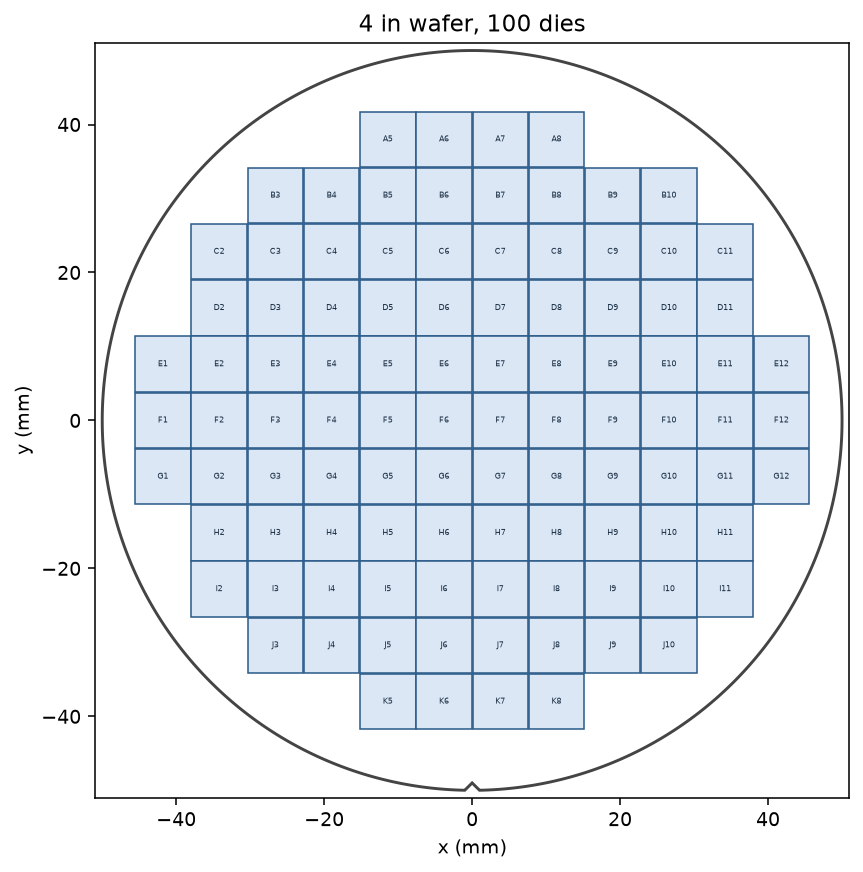

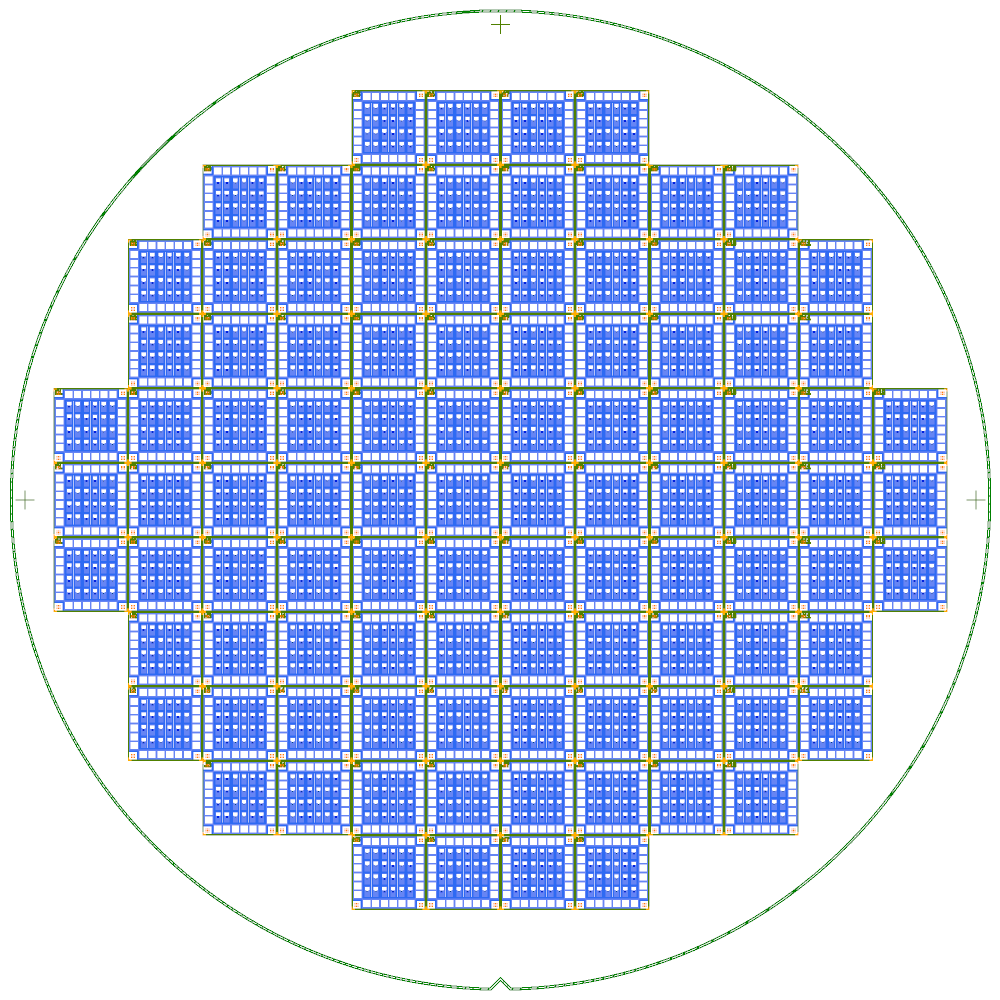

In [3]:
w4 = Wafer(diameter_mm=100, die_mm=7.5, street_mm=0.1, edge_mm=3.0)  # notch on the bottom edge by default
print("dies:", w4.die_count, "| first:", w4.dies[0].name, "| last:", w4.dies[-1].name)
w4.write(OUT / "wafer_4in_dense_75.oas", chips={7.5: CHIPS["chip06"]})
display(Markdown(w4.table_markdown(limit=8) + "\n\n... (the full table is in `wafer_4in_dense_75.csv`)"))
w4.plot_map(OUT / "map_4in_dense_75.png")  # the die map with the names
display(Image(str(OUT / "map_4in_dense_75.png"), width=600))
snapshot(OUT / "wafer_4in_dense_75.oas", OUT / "wafer_4in_dense_75.png", size=(1000, 1000))  # the layout, rendered by KLayout
Image(str(OUT / "wafer_4in_dense_75.png"), width=600)

## 3 Four inch, centred with a radius

`packing="centred"` fills only a circle of `radius_mm` around the packing centre, which is the wafer centre plus
`offset_mm`. A die is kept when all four corners are inside the circle (and inside the usable disc). Here: 30 mm
radius, centre moved 6 mm right and 4 mm down.

dies: 37


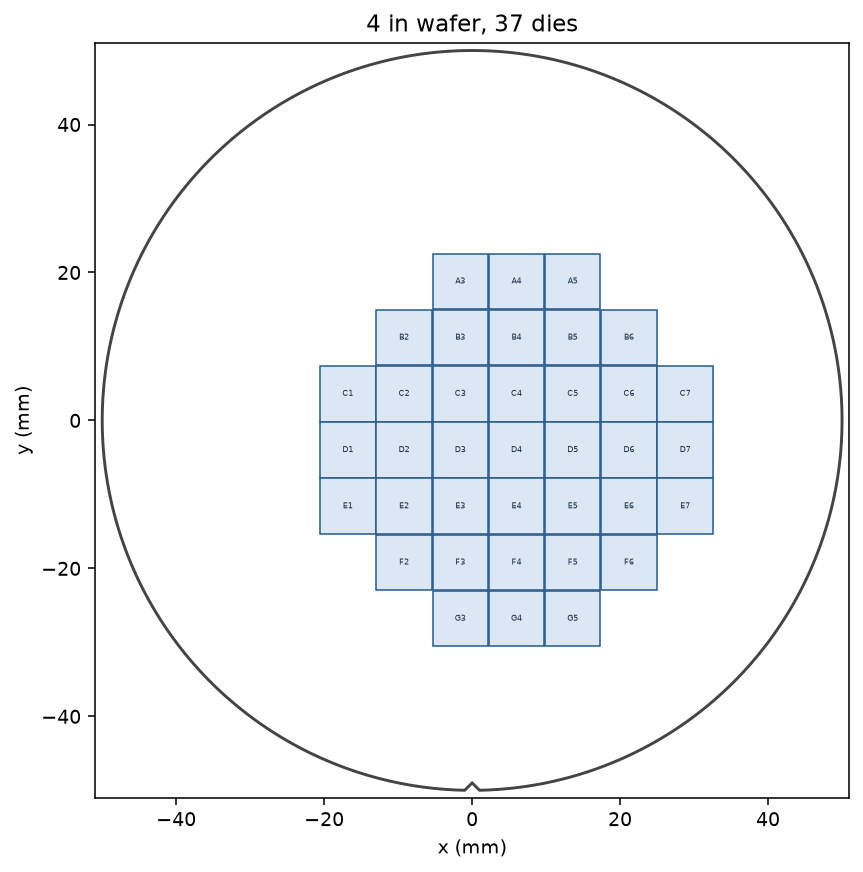

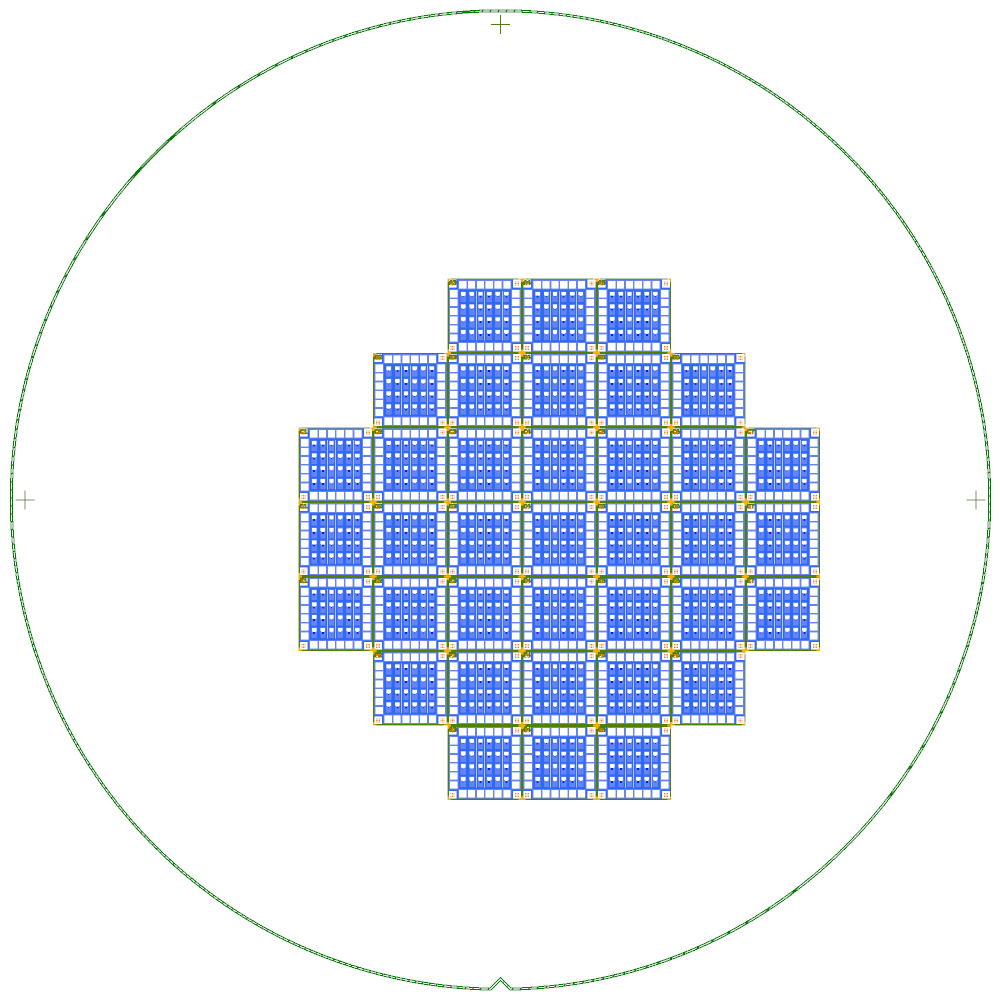

In [4]:
w4c = Wafer(diameter_mm=100, die_mm=7.5, packing="centred", radius_mm=30, offset_mm=(6.0, -4.0))
print("dies:", w4c.die_count)
w4c.write(OUT / "wafer_4in_centred_75.oas", chips={7.5: CHIPS["chip06"]})
w4c.plot_map(OUT / "map_4in_centred_75.png")  # the die map with the names
display(Image(str(OUT / "map_4in_centred_75.png"), width=600))
snapshot(OUT / "wafer_4in_centred_75.oas", OUT / "wafer_4in_centred_75.png", size=(1000, 1000))  # the layout, rendered by KLayout
Image(str(OUT / "wafer_4in_centred_75.png"), width=600)

## 4 Four inch, mixed die sizes

`bands=[(die_mm, n_rows), ...]` stacks rows of one die size from top to bottom (the stack is centred); every row is
filled with as many dies as fit. Columns are counted from the left of each row. The three chips go on the dies of
their size: `chips={5: ..., 7.5: ..., 10: ...}`.

dies: 105 by size: {5: 42, 7.5: 38, 10: 25}


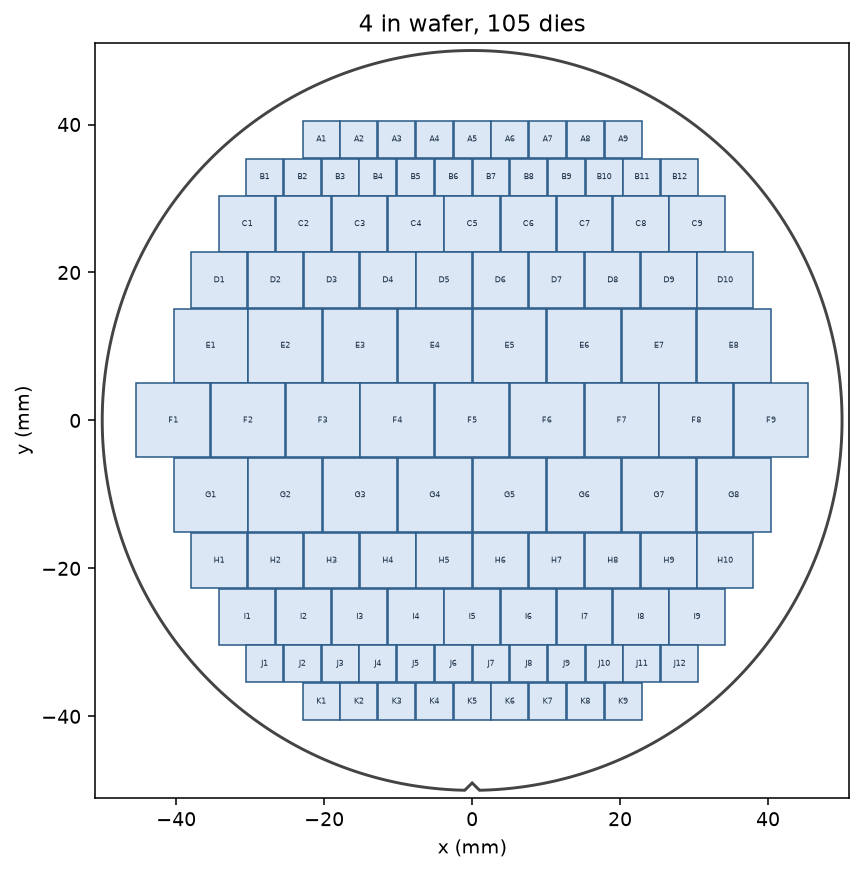

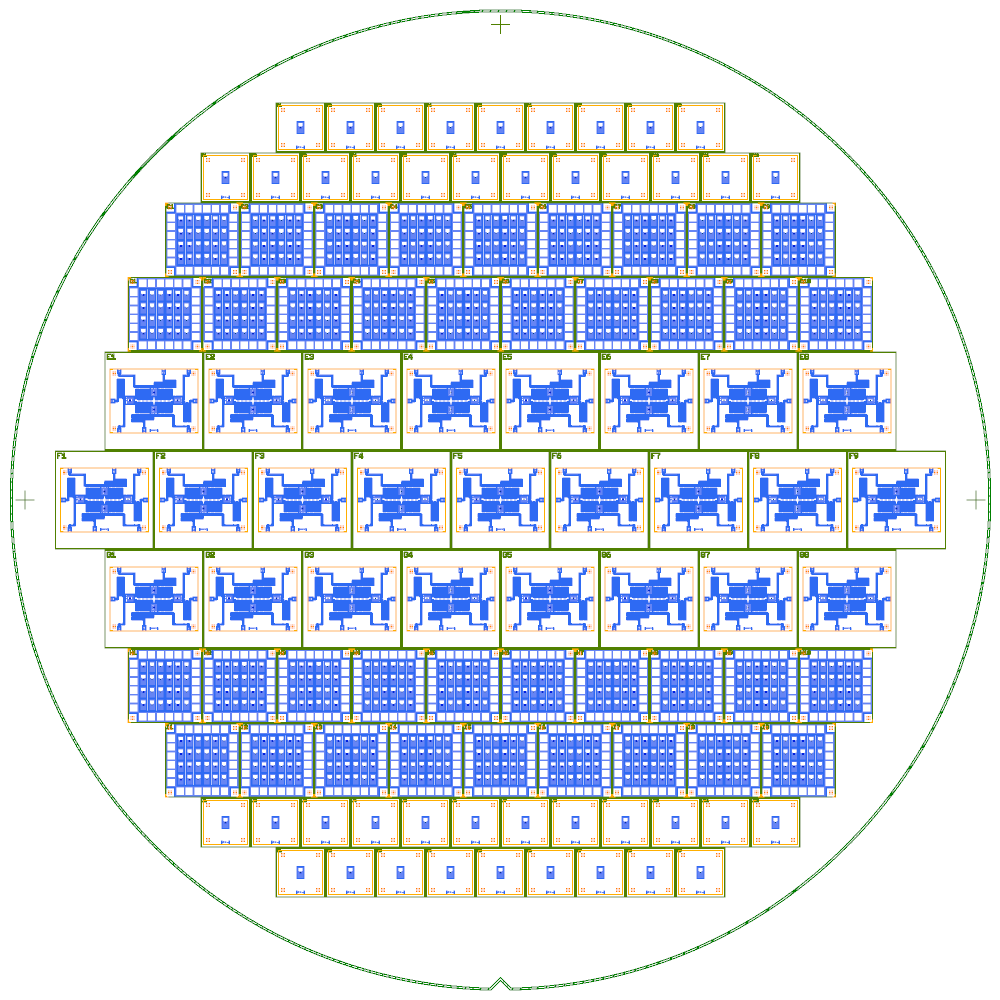

In [5]:
w4m = Wafer(diameter_mm=100, bands=[(5, 2), (7.5, 2), (10, 3), (7.5, 2), (5, 2)])
print("dies:", w4m.die_count, "by size:", w4m.counts_by_size())
w4m.write(OUT / "wafer_4in_mixed.oas", chips={5: CHIPS["mini"], 7.5: CHIPS["chip06"], 10: CHIPS["m51"]})
w4m.plot_map(OUT / "map_4in_mixed.png")  # the die map with the names
display(Image(str(OUT / "map_4in_mixed.png"), width=600))
snapshot(OUT / "wafer_4in_mixed.oas", OUT / "wafer_4in_mixed.png", size=(1000, 1000))  # the layout, rendered by KLayout
Image(str(OUT / "wafer_4in_mixed.png"), width=600)

## 5 Six inch

A 150 mm wafer: 10 mm dies dense (each carries the 9.0 x 6.5 mm Metal chip, centred on its die), and 7.5 mm dies in a
centred 45 mm circle.

6 in dense, 10 mm: 137


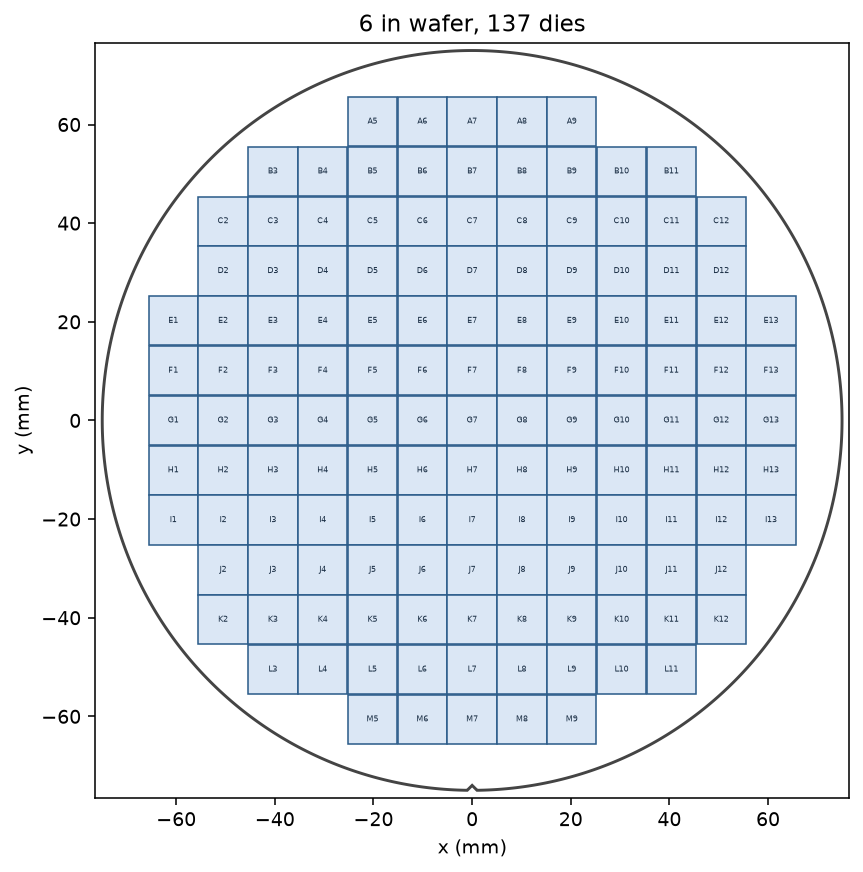

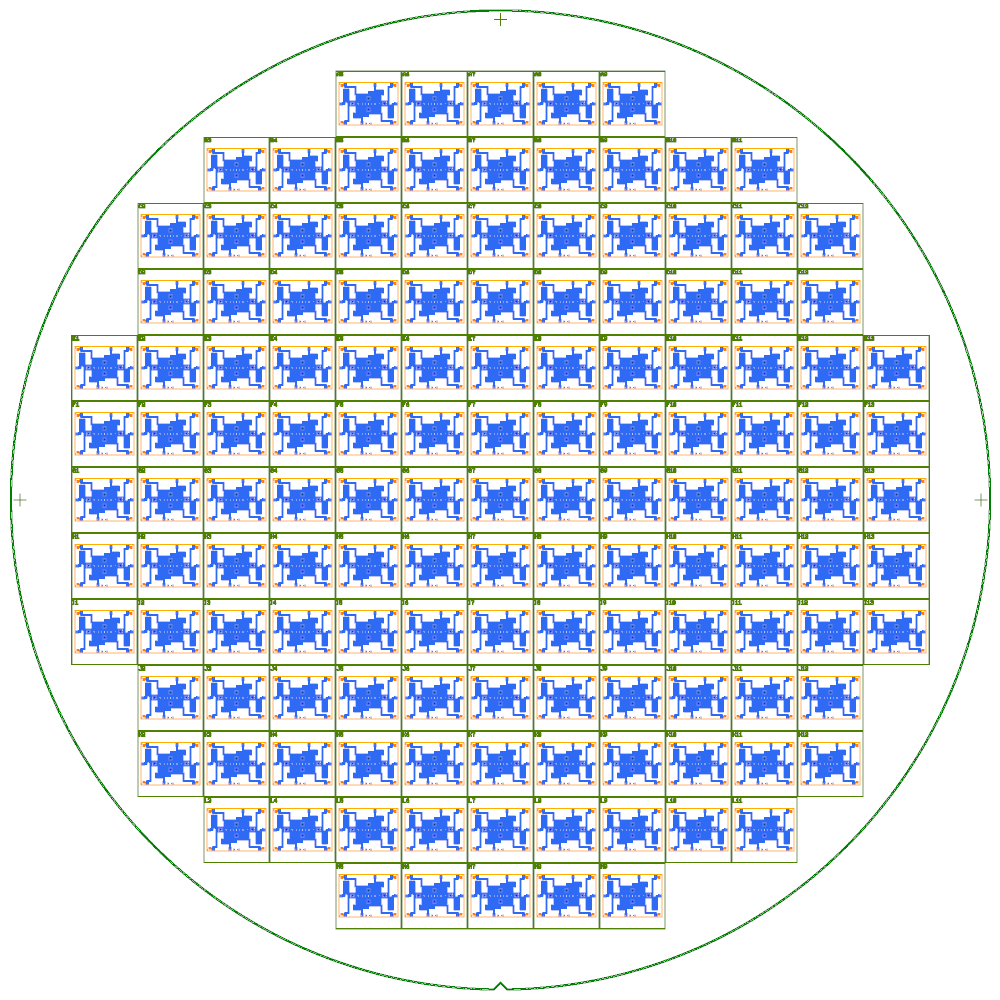

In [6]:
w6 = Wafer(diameter_mm=150, die_mm=10)
print("6 in dense, 10 mm:", w6.die_count)
w6.write(OUT / "wafer_6in_dense_10.oas", chips={10: CHIPS["m51"]})
w6.plot_map(OUT / "map_6in_dense_10.png")  # the die map with the names
display(Image(str(OUT / "map_6in_dense_10.png"), width=600))
snapshot(OUT / "wafer_6in_dense_10.oas", OUT / "wafer_6in_dense_10.png", size=(1000, 1000))  # the layout, rendered by KLayout
Image(str(OUT / "wafer_6in_dense_10.png"), width=600)

6 in centred, 7.5 mm, radius 45: 89


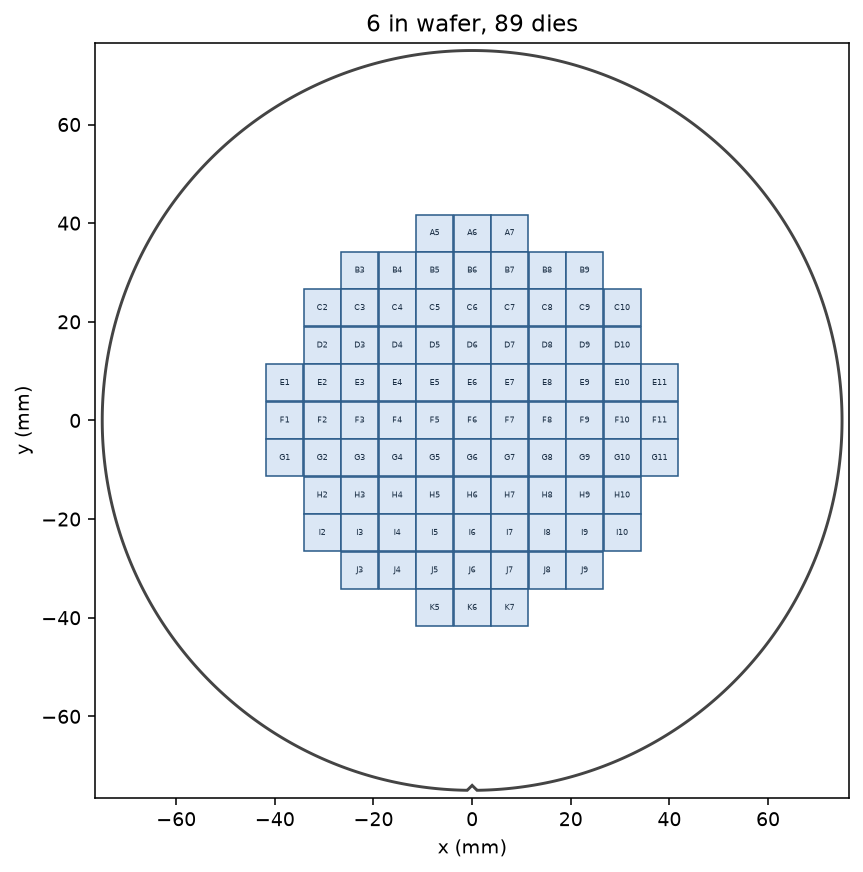

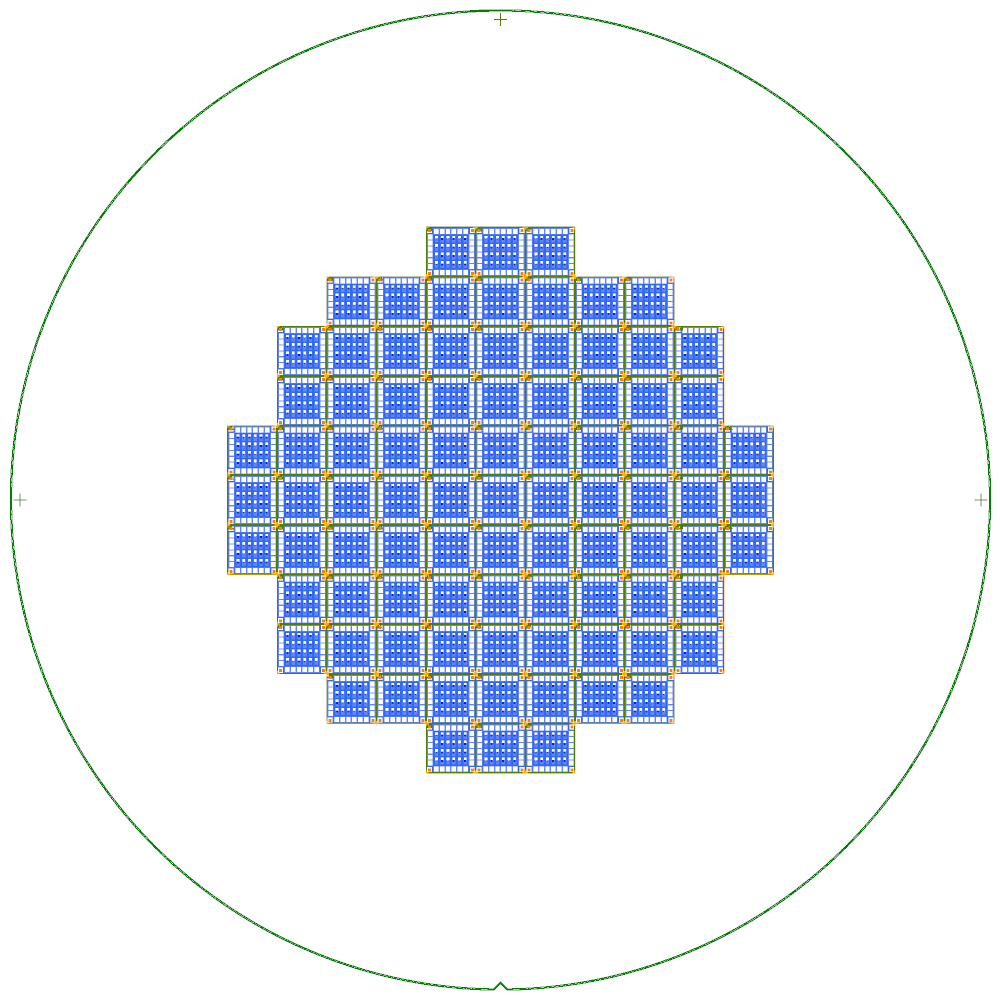

In [7]:
w6c = Wafer(diameter_mm=150, die_mm=7.5, packing="centred", radius_mm=45)
print("6 in centred, 7.5 mm, radius 45:", w6c.die_count)
w6c.write(OUT / "wafer_6in_centred_75.oas", chips={7.5: CHIPS["chip06"]})
w6c.plot_map(OUT / "map_6in_centred_75.png")  # the die map with the names
display(Image(str(OUT / "map_6in_centred_75.png"), width=600))
snapshot(OUT / "wafer_6in_centred_75.oas", OUT / "wafer_6in_centred_75.png", size=(1000, 1000))  # the layout, rendered by KLayout
Image(str(OUT / "wafer_6in_centred_75.png"), width=600)

## 6 Zoom on a few dies

`snapshot(..., box=(x0, y0, x1, y1))` zooms to a region in µm. The dies below are looked up by name. The label sits in
the top-left corner of the die on 501/0; the thin frame around each die is the die outline (also 501/0).

zoom on ['F7', 'F8']


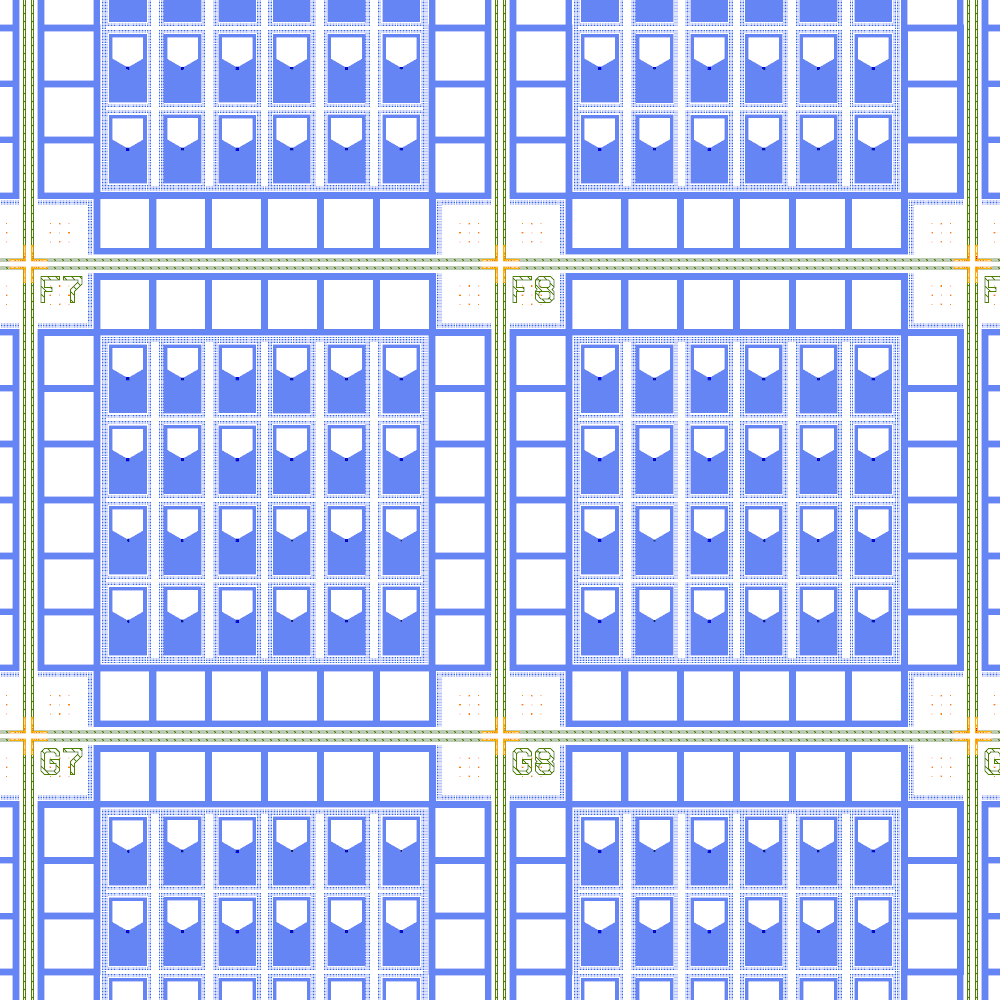

In [8]:
def zoom(wafer, oas, names, png):
    boxes = [wafer.die(n).box_um for n in names]
    x0, y0 = min(b[0] for b in boxes) - 500, min(b[1] for b in boxes) - 500
    x1, y1 = max(b[2] for b in boxes) + 500, max(b[3] for b in boxes) + 500
    snapshot(oas, png, size=(1000, 1000), box=(x0, y0, x1, y1))
    return Image(str(png))


two = [w4.dies[len(w4.dies) // 2].name, w4.dies[len(w4.dies) // 2 + 1].name]
print("zoom on", two)
zoom(w4, OUT / "wafer_4in_dense_75.oas", two, OUT / "zoom_4in_dense.png")

zoom on ['E1', 'C1']


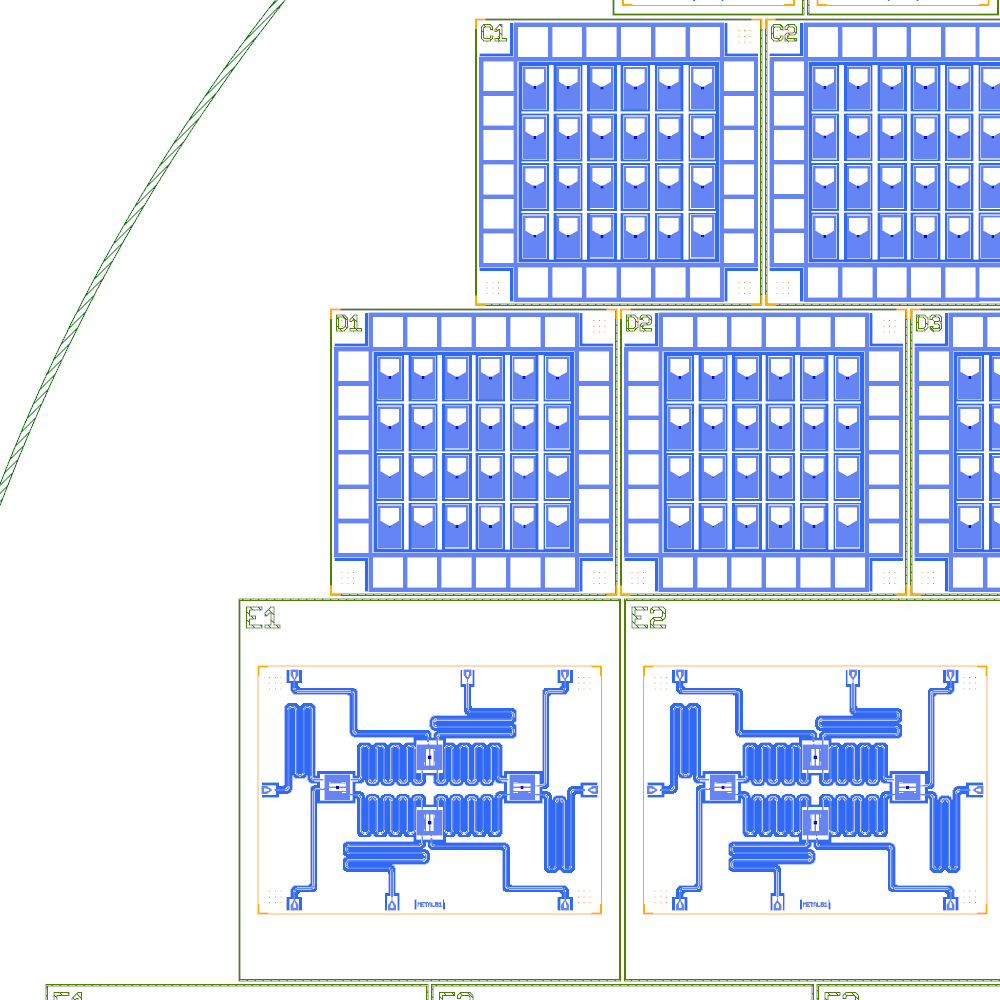

In [9]:
mid = [d.name for d in w4m.dies if d.size_mm == 10][:1] + [d.name for d in w4m.dies if d.size_mm == 7.5][:1]
print("zoom on", mid)
zoom(w4m, OUT / "wafer_4in_mixed.oas", mid, OUT / "zoom_4in_mixed.png")

In [10]:
for name, w in [
    ("4 in dense 7.5", w4),
    ("4 in centred 7.5 r30", w4c),
    ("4 in mixed", w4m),
    ("6 in dense 10", w6),
    ("6 in centred 7.5 r45", w6c),
]:
    print(f"{name:22s} {w.die_count:4d} dies", w.counts_by_size())

4 in dense 7.5          100 dies {7.5: 100}
4 in centred 7.5 r30     37 dies {7.5: 37}
4 in mixed              105 dies {5: 42, 7.5: 38, 10: 25}
6 in dense 10           137 dies {10: 137}
6 in centred 7.5 r45     89 dies {7.5: 89}
